# Formative 2 - Multimodal Data Preprocessing
## Part 2: Facial Image Collection, Augmentation and Feature Extraction

**Project component:** input data for the face recognition model (the first security check).

### Objectives
1. Load and display the three required expressions (neutral, smiling, surprised) for every member.
2. Detect and crop the face so the model learns from the face, not the background.
3. Apply several augmentations per image to imitate real login conditions.
4. Extract colour histogram, LBP texture and HOG shape features, and save them to `datasets/image_features.csv`.

All processing code lives in [`src/image_pipeline.py`](../src/image_pipeline.py). The command-line demo reuses the same
functions on a new photo, so training and login always see identical preprocessing.

### Data layout
```
data/images/<member>/<member>_<expression>.jpg
```
The folder name is the identity label. The expression is read from the file name.

## 1. Environment setup

Works locally from a clone of the repository and on Google Colab (the cell clones the repository when needed).

In [1]:
import os
import subprocess
import sys
import warnings
from pathlib import Path

REPO_URL = "https://github.com/mutaganzwa-desire/multimodal_data_preprocessing.git"


def find_repo_root() -> Path:
    """Find the repository folder, cloning it first when running on Colab."""
    for folder in [Path.cwd(), *Path.cwd().parents]:
        if (folder / "src" / "image_pipeline.py").exists():
            return folder
    if "google.colab" in sys.modules:
        target = Path("/content/multimodal_data_preprocessing")
        if not target.exists():
            subprocess.run(["git", "clone", "-q", REPO_URL, str(target)], check=True)
        return target
    raise FileNotFoundError("Open this notebook from inside the repository.")


REPO_ROOT = find_repo_root()
os.chdir(REPO_ROOT)
sys.path.insert(0, str(REPO_ROOT))
warnings.filterwarnings("ignore", category=FutureWarning)
print("Repository:", REPO_ROOT)

Repository: /home/rca/projects/personal/learning/alu-formative2-mlp


In [2]:
import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from skimage.feature import hog, local_binary_pattern
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

from src import image_pipeline as ip

pd.set_option("display.max_columns", 20)
pd.set_option("display.width", 140)
plt.rcParams["figure.dpi"] = 80
# Photo grids are stored as JPEG so the saved notebook stays small.
%config InlineBackend.figure_formats = ["jpeg"]

## 2. Image inventory and completeness check

Every member must have one neutral, one smiling and one surprised photo with consistent naming.

In [3]:
images = ip.find_images()
members = sorted(images["member"].unique())

inventory = images.assign(
    file=images["path"].map(lambda p: p.name),
    width=images["path"].map(lambda p: ip.load_image(p).shape[1]),
    height=images["path"].map(lambda p: ip.load_image(p).shape[0]),
    size_kb=images["path"].map(lambda p: round(p.stat().st_size / 1024)),
).drop(columns="path")
display(inventory)

coverage = pd.crosstab(images["member"], images["expression"]).reindex(columns=list(ip.EXPRESSIONS), fill_value=0)
display(coverage)
missing = [(m, e) for m in coverage.index for e in coverage.columns if coverage.loc[m, e] == 0]
print("Missing expressions:", missing or "none, every member has all three")

,member,expression,file,width,height,size_kb
0,alain,neutral,alain_neutral.jpg,1200,1600,500
1,alain,smiling,alain_smiling.jpg,1200,1600,531
2,alain,surprised,alain_surprised.jpg,1200,1600,485
3,desire,neutral,desire_neutral.jpg,1440,1426,157
4,desire,smiling,desire_smiling.jpg,1440,3200,1171
5,desire,surprised,desire_surprised.jpg,384,432,68


expression,neutral,smiling,surprised
member,,,
alain,1,1,1
desire,1,1,1


Missing expressions: none, every member has all three


**Interpretation:** both members have all three expressions, named consistently as `<member>_<expression>.jpg`. Resolution varies a lot: Alain's photos are 1200 x 1600 phone shots, while Desire's range from 384 x 432 (the surprised photo, which is a picture of a printed photo) to 1440 x 3200. Every face is cropped and resized to 128 x 128 before feature extraction, so these differences do not change the feature vector, although the low-resolution surprised photo carries less fine detail.

## 3. Sample pictures of each member

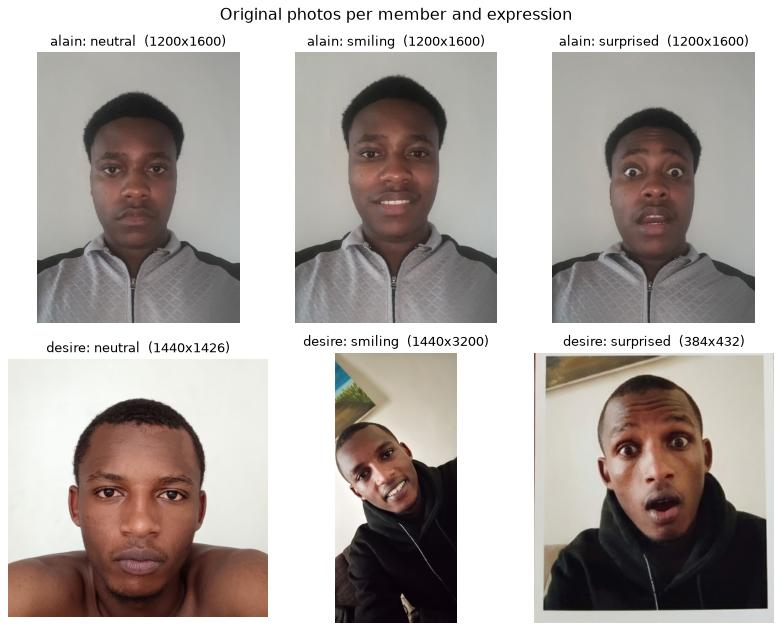

In [4]:
fig, axes = plt.subplots(len(members), 3, figsize=(10, 4 * len(members)))
for r, member in enumerate(members):
    for c, expression in enumerate(ip.EXPRESSIONS):
        ax = axes[r, c]
        match = images[(images["member"] == member) & (images["expression"] == expression)]
        if match.empty:
            ax.text(0.5, 0.5, "missing", ha="center", va="center")
        else:
            img = ip.load_image(match["path"].iloc[0])
            ax.imshow(img)
            ax.set_title(f"{member}: {expression}  ({img.shape[1]}x{img.shape[0]})")
        ax.axis("off")
fig.suptitle("Original photos per member and expression", fontsize=14)
fig.tight_layout()
plt.show()

**Interpretation:** the three expressions are easy to tell apart for both members: a relaxed closed mouth for neutral, visible teeth for smiling, and raised eyebrows with an open mouth for surprised. Backgrounds and lighting differ between members and even between photos of the same member (a plain grey wall for Alain; a white wall, a room interior and a printed photo for Desire). That is a strong reason to crop to the face before extracting features, otherwise a model could learn the room instead of the person.

## 4. Face detection and cropping

The photos differ in framing, resolution and background, so features are taken from the face only:

1. Shrink the photo to a longest side of 800 px for speed.
2. Run OpenCV's Haar frontal face detector.
3. The detector only finds **upright** faces, so the photo is also tried rotated by 10, 20 and 30 degrees either way.
4. A candidate counts only if eyes are found in the upper part of the box. This rejects false hits such as a chin.
5. The candidate with the smallest rotation wins, so straight photos are never rotated.
6. Crop a square around the face with a 15% margin and resize it to 128 x 128 px.

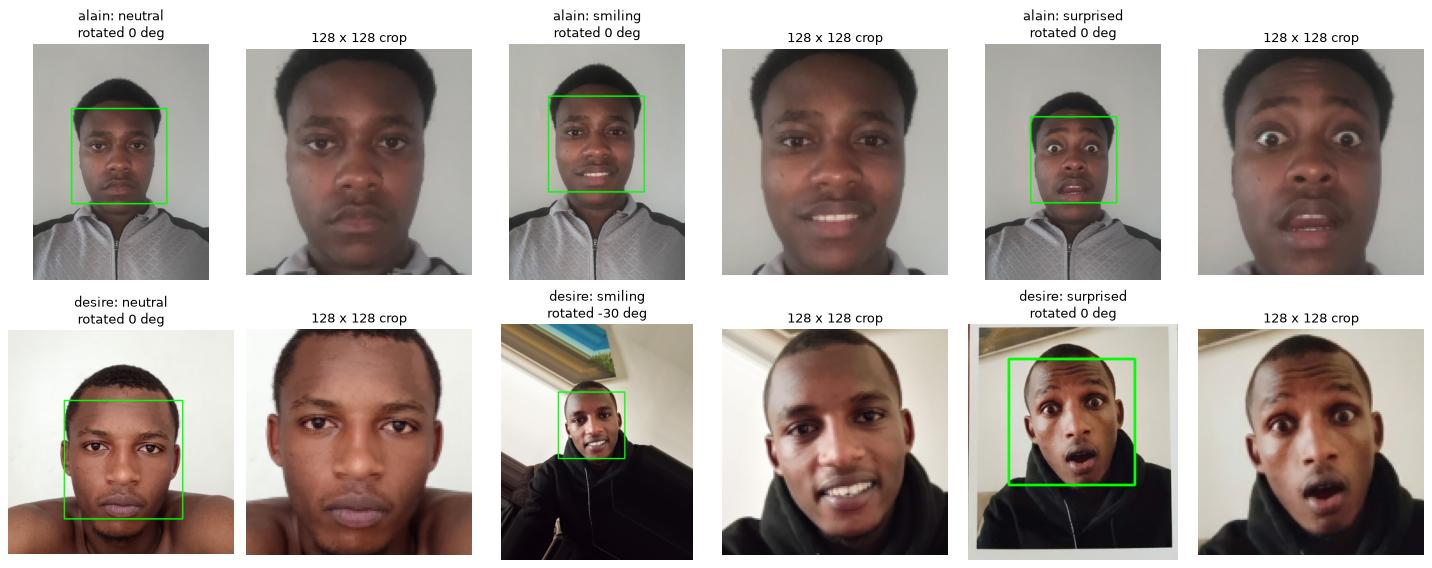

,photo,face_found,rotation_deg
0,alain_neutral.jpg,True,0
1,alain_smiling.jpg,True,0
2,alain_surprised.jpg,True,0
3,desire_neutral.jpg,True,0
4,desire_smiling.jpg,True,-30
5,desire_surprised.jpg,True,0


In [5]:
fig, axes = plt.subplots(len(members), 6, figsize=(18, 3.6 * len(members)))
detections = []
for r, member in enumerate(members):
    for c, expression in enumerate(ip.EXPRESSIONS):
        path = images[(images["member"] == member) & (images["expression"] == expression)]["path"].iloc[0]
        upright, box, angle = ip.locate_face(ip.load_image(path))
        shown = upright.copy()
        if box is not None:
            x, y, w, h = box
            cv2.rectangle(shown, (x, y), (x + w, y + h), (0, 255, 0), 4)
        axes[r, 2 * c].imshow(shown)
        axes[r, 2 * c].set_title(f"{member}: {expression}\nrotated {angle} deg")
        axes[r, 2 * c + 1].imshow(ip.crop_face(upright, box))
        axes[r, 2 * c + 1].set_title("128 x 128 crop")
        detections.append({"photo": path.name, "face_found": box is not None, "rotation_deg": angle})
for ax in axes.ravel():
    ax.axis("off")
fig.tight_layout()
plt.show()
display(pd.DataFrame(detections))

**Interpretation:** a face was found in all six photos. Five were upright and used as they are. In `desire_smiling.jpg` the head is tilted by about 30 degrees, and the upright detector first latched onto the chin. The eye check rejected that box and the 30 degree rotation found the real face, which also straightens it. All crops are now centred on the face at the same scale, so the features describe the person rather than the framing.

## 5. Augmentation

Each face crop gets **7 augmentations** plus the original, giving 8 versions per photo. Each one imitates a condition
the face model may meet at login time:

| Augmentation | Imitates |
|---|---|
| `rotate_+15`, `rotate_-15` | head tilted to either side |
| `flip_horizontal` | mirrored front-camera selfie |
| `grayscale` | black and white or colour-shifted camera |
| `brightness_up`, `brightness_down` | bright window or dim room |
| `gaussian_noise` | grainy low-light sensor |

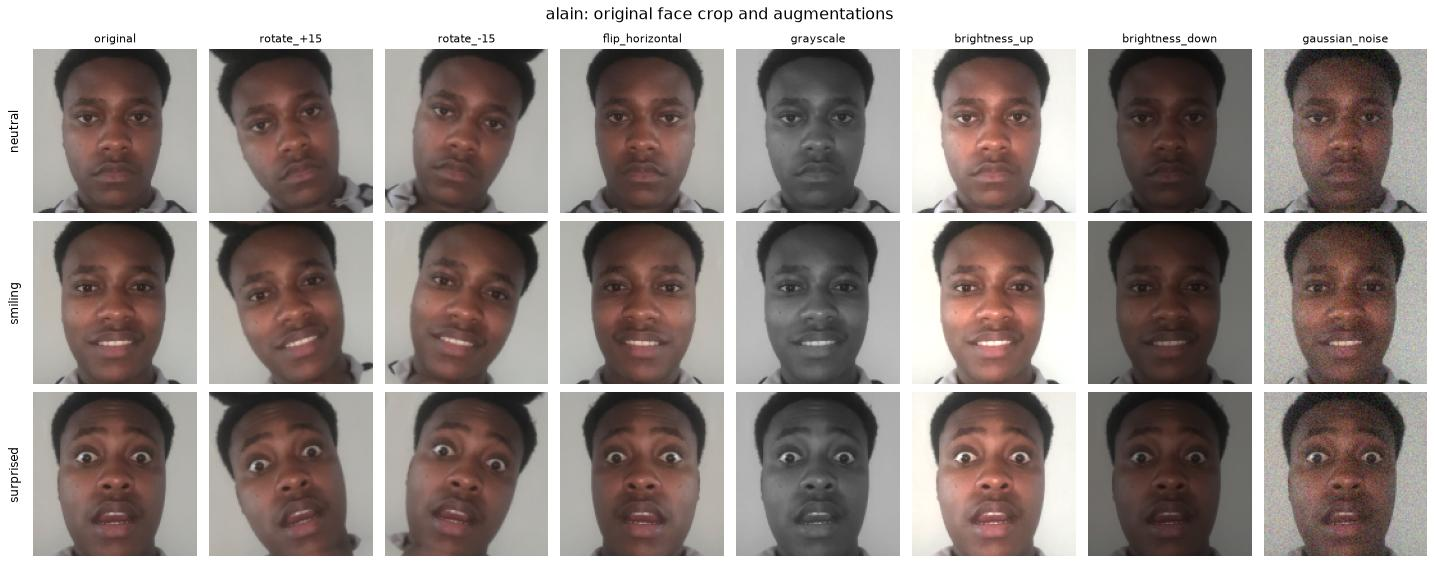

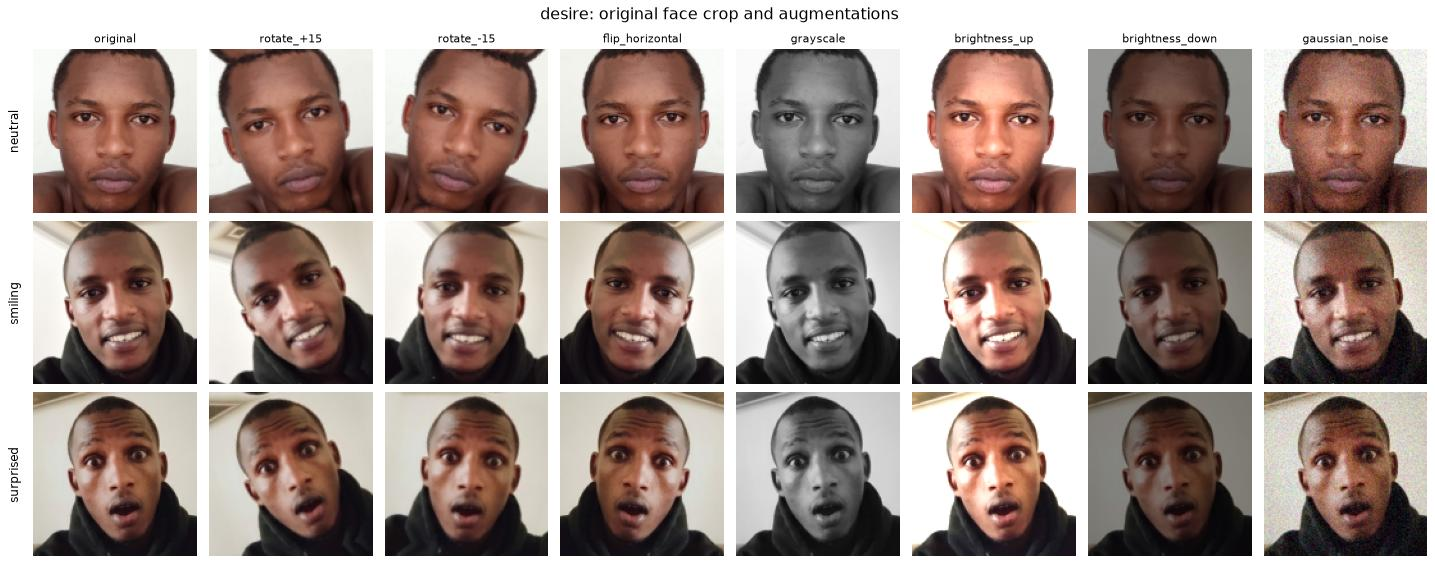

In [6]:
for member in members:
    fig, axes = plt.subplots(3, len(ip.AUGMENTATIONS), figsize=(18, 7.2))
    for r, expression in enumerate(ip.EXPRESSIONS):
        path = images[(images["member"] == member) & (images["expression"] == expression)]["path"].iloc[0]
        face, _ = ip.load_face(path)
        for c, (name, version) in enumerate(ip.augment(face).items()):
            axes[r, c].imshow(version)
            axes[r, c].axis("off")
            if r == 0:
                axes[r, c].set_title(name, fontsize=10)
        axes[r, 0].text(-10, 64, expression, rotation=90, va="center", ha="right", fontsize=11)
    fig.suptitle(f"{member}: original face crop and augmentations", fontsize=14)
    fig.tight_layout()
    plt.show()

**Interpretation:** every augmentation keeps the face recognisable, which is the goal: they add realistic variation without changing who is in the picture. The rotations reflect the border instead of adding black corners, so a model cannot learn to spot artificial edges. Grayscale removes colour completely, which forces the model to rely on texture (LBP) and shape (HOG) for those rows rather than on skin tone or lighting colour.

## 6. Feature extraction

Three complementary descriptors are computed on every face crop (532 values in total):

| Block | Columns | Size | What it captures |
|---|---|---|---|
| Colour histogram | `hist_0` to `hist_47` | 3 channels x 16 bins | skin tone and lighting |
| LBP texture | `lbp_0` to `lbp_159` | 4 x 4 grid x 10 uniform patterns | local skin and feature texture, robust to brightness |
| HOG shape | `hog_0` to `hog_323` | 3 x 3 blocks x 4 cells x 9 orientations | outline of eyes, nose, mouth and jaw |

The histograms are normalised, so photo resolution does not change the scale. The figure below shows what each
descriptor sees on one face.

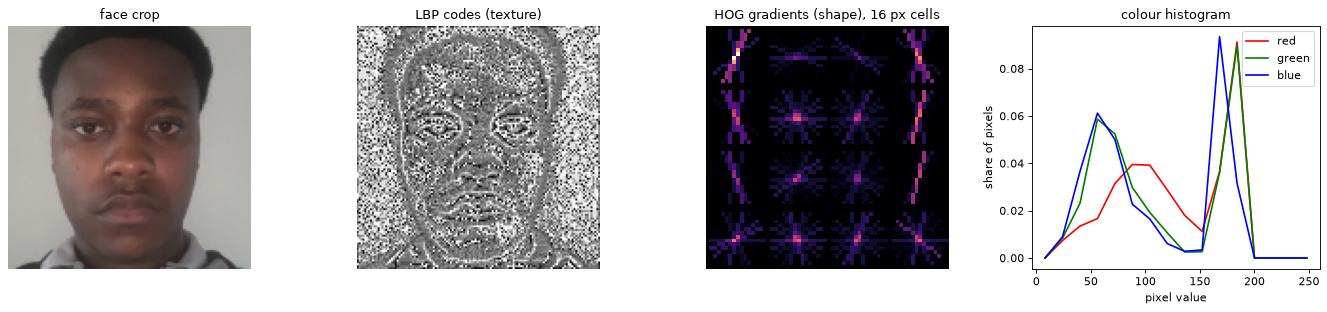

In [7]:
example_path = images[(images["member"] == members[0]) & (images["expression"] == "neutral")]["path"].iloc[0]
face, _ = ip.load_face(example_path)
gray = cv2.cvtColor(face, cv2.COLOR_RGB2GRAY)
_, hog_image = hog(cv2.resize(gray, (ip.HOG_SIZE, ip.HOG_SIZE)), orientations=9,
                   pixels_per_cell=(ip.HOG_CELL, ip.HOG_CELL), cells_per_block=(2, 2), visualize=True)
lbp_image = local_binary_pattern(gray, ip.LBP_POINTS, ip.LBP_RADIUS, method="uniform")

fig, axes = plt.subplots(1, 4, figsize=(17, 4))
axes[0].imshow(face); axes[0].set_title("face crop")
axes[1].imshow(lbp_image, cmap="gray"); axes[1].set_title("LBP codes (texture)")
axes[2].imshow(hog_image, cmap="magma"); axes[2].set_title("HOG gradients (shape), 16 px cells")
for ax in axes[:3]:
    ax.axis("off")
hist = ip.color_histogram(face).reshape(3, -1)
centres = np.arange(ip.HIST_BINS) * (256 / ip.HIST_BINS) + 8
for channel, colour in zip(hist, ["red", "green", "blue"]):
    axes[3].plot(centres, channel, color=colour, label=colour)
axes[3].set_title("colour histogram"); axes[3].set_xlabel("pixel value"); axes[3].set_ylabel("share of pixels")
axes[3].legend()
fig.tight_layout()
plt.show()

**Interpretation:** the LBP map outlines the eyes, nostrils, mouth and hairline, while the flat wall turns into fine random texture. The HOG panel shows the dominant edge direction in each 16 px cell, the same coarse grid used for the features: it records the overall layout of the face rather than fine detail, which makes it tolerant to small shifts. The colour histogram has two peaks: the darker, wider one is skin and hair, and the bright narrow one is the grey wall left in the crop margin.

## 7. Build and save `image_features.csv`

One row per (photo, augmentation). Metadata columns come first, followed by the 532 feature columns.

In [8]:
features = ip.build_feature_table()
features.to_csv(ip.OUTPUT_CSV, index=False, float_format="%.6f")

feature_cols = ip.feature_columns(features)
metadata_cols = [c for c in features.columns if c not in feature_cols]
print(f"Saved {ip.OUTPUT_CSV.relative_to(REPO_ROOT)}: {features.shape[0]} rows, "
      f"{len(metadata_cols)} metadata columns, {len(feature_cols)} feature columns")
print("Feature blocks:", {b: sum(c.startswith(b + "_") for c in feature_cols) for b in ["hist", "lbp", "hog"]})
display(features[metadata_cols + feature_cols[:3] + ["lbp_0", "hog_0"]].head(10))

Saved datasets/image_features.csv: 48 rows, 7 metadata columns, 532 feature columns
Feature blocks: {'hist': 48, 'lbp': 160, 'hog': 324}


,image_id,member,expression,augmentation,source_image,face_detected,face_angle,hist_0,hist_1,hist_2,lbp_0,hog_0
0,alain_neutral__original,alain,neutral,original,data/images/alain/alain_neutral.jpg,True,0,0.000000,0.007365,0.013468,0.016602,0.275657
1,alain_neutral__rotate_+15,alain,neutral,rotate_+15,data/images/alain/alain_neutral.jpg,True,0,0.000000,0.007528,0.016886,0.011719,0.288805
2,alain_neutral__rotate_-15,alain,neutral,rotate_-15,data/images/alain/alain_neutral.jpg,True,0,0.000000,0.010925,0.012919,0.016602,0.267734
3,alain_neutral__flip_horizontal,alain,neutral,flip_horizontal,data/images/alain/alain_neutral.jpg,True,0,0.000000,0.007365,0.013468,0.014648,0.297845
4,alain_neutral__grayscale,alain,neutral,grayscale,data/images/alain/alain_neutral.jpg,True,0,0.000000,0.007955,0.018270,0.016602,0.275657
5,alain_neutral__brightness_up,alain,neutral,brightness_up,data/images/alain/alain_neutral.jpg,True,0,0.000000,0.000000,0.010254,0.020508,0.274834
6,alain_neutral__brightness_down,alain,neutral,brightness_down,data/images/alain/alain_neutral.jpg,True,0,0.000977,0.025411,0.042501,0.010742,0.273553
7,alain_neutral__gaussian_noise,alain,neutral,gaussian_noise,data/images/alain/alain_neutral.jpg,True,0,0.001404,0.007406,0.014242,0.127930,0.275777
8,alain_smiling__original,alain,smiling,original,data/images/alain/alain_smiling.jpg,True,0,0.000000,0.006734,0.012268,0.013672,0.289216
9,alain_smiling__rotate_+15,alain,smiling,rotate_+15,data/images/alain/alain_smiling.jpg,True,0,0.000000,0.006042,0.015279,0.008789,0.293537


In [9]:
# Validation of the saved file
saved = pd.read_csv(ip.OUTPUT_CSV)
checks = {
    "rows = photos x versions": len(saved) == len(images) * len(ip.AUGMENTATIONS),
    "no missing values": not saved.isna().any().any(),
    "unique image_id": saved["image_id"].is_unique,
    "every photo had a face detected": bool(saved["face_detected"].all()),
    "every member has 3 expressions": bool((saved.groupby("member")["expression"].nunique() == 3).all()),
}
display(pd.Series(checks, name="passed").to_frame())
display(pd.crosstab([saved["member"], saved["expression"]], saved["augmentation"]))

,passed
rows = photos x versions,True
no missing values,True
unique image_id,True
every photo had a face detected,True
every member has 3 expressions,True


augmentation       brightness_down  brightness_up  flip_horizontal  gaussian_noise  grayscale  original  rotate_+15  rotate_-15
member expression                                                                                                              
alain  neutral                   1              1                1               1          1         1           1           1
       smiling                   1              1                1               1          1         1           1           1
       surprised                 1              1                1               1          1         1           1           1
desire neutral                   1              1                1               1          1         1           1           1
       smiling                   1              1                1               1          1         1           1           1
       surprised                 1              1                1               1          1         1           1           1

## 8. Do the features separate the members?

A quick look before any model is trained: standardise the 532 features and project them onto two principal components.
If each member forms their own region, the face recognition model has a usable signal.

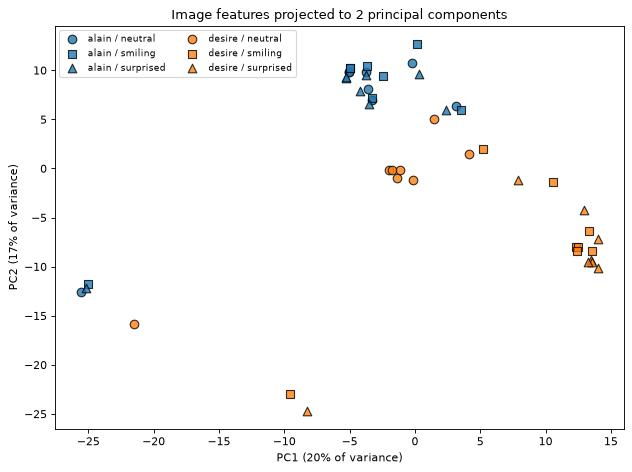

In [10]:
X = StandardScaler().fit_transform(saved[feature_cols])
pca = PCA(n_components=2, random_state=ip.SEED)
coords = pca.fit_transform(X)

fig, ax = plt.subplots(figsize=(8, 6))
markers = {"neutral": "o", "smiling": "s", "surprised": "^"}
colours = dict(zip(members, plt.cm.tab10.colors))
for (member, expression), idx in saved.groupby(["member", "expression"]).groups.items():
    ax.scatter(coords[idx, 0], coords[idx, 1], c=[colours[member]], marker=markers[expression],
               s=60, alpha=0.8, edgecolor="k", label=f"{member} / {expression}")
ax.set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]:.0%} of variance)")
ax.set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]:.0%} of variance)")
ax.set_title("Image features projected to 2 principal components")
ax.legend(fontsize=8, ncol=2)
fig.tight_layout()
plt.show()

**Identity signal check (not the final model).** Each photo is held out in turn with all 8 of its versions, and every
held-out version is labelled with the member of its nearest neighbour among the other photos. Holding out whole photos
matters: the versions of one photo are near copies, so a random row split would look far better than reality.

In [11]:
from sklearn.neighbors import KNeighborsClassifier

blocks = {"all features": feature_cols,
          **{name: [c for c in feature_cols if c.startswith(name + "_")] for name in ["hist", "lbp", "hog"]}}
results = {}
for block, cols in blocks.items():
    correct = 0
    for photo in saved["source_image"].unique():
        train, test = saved[saved["source_image"] != photo], saved[saved["source_image"] == photo]
        scaler = StandardScaler().fit(train[cols])
        knn = KNeighborsClassifier(n_neighbors=1).fit(scaler.transform(train[cols]), train["member"])
        correct += (knn.predict(scaler.transform(test[cols])) == test["member"]).sum()
    results[block] = correct / len(saved)
display(pd.Series(results, name="leave-one-photo-out accuracy").round(2).to_frame())
print(f"Chance level with {len(members)} members: {1 / len(members):.2f}")

,leave-one-photo-out accuracy
all features,0.90
hist,0.85
lbp,0.77
hog,0.85


Chance level with 2 members: 0.50


**Interpretation:** the first two components explain 37% of the variance. Alain's rows (blue) and Desire's rows (orange) occupy different regions, and each member's expressions fall close together, which is what a face recognition model needs. Two patterns stand out. First, the six `gaussian_noise` rows form their own group at the edge of the plot, because pixel noise changes the LBP texture codes a lot; it is a deliberately hard case. Second, Desire's neutral photo sits apart from the smiling and surprised ones, because it was taken in a different place and light.

The nearest-neighbour check confirms that the features carry identity: with all 532 features, 0.90 of held-out versions are matched to the right member, against 0.50 by chance. The colour histogram and HOG are the strongest single blocks; LBP is weaker on its own because of its sensitivity to noise, but it adds information when combined.

## 9. Summary and notes for the face recognition model

* **`datasets/image_features.csv`**: 48 rows (2 members x 3 expressions x 8 versions), 7 metadata columns and 532 feature columns (48 colour histogram, 160 LBP, 324 HOG). All validation checks pass.
* **Target column:** `member`. `expression` and `augmentation` are kept for analysis, not as model inputs.
* **Split by `source_image`, never by row.** The 8 versions of one photo are near copies; a random split would put copies of the same photo in both training and test sets and inflate the scores. Use `GroupKFold` or leave-one-photo-out with `groups=source_image`.
* **Scaling:** standardise the features for Logistic Regression; Random Forest and XGBoost do not need it.
* **At login time** call `ip.features_for_path(path)` to turn a new photo into the same 532 features. For the unauthorised attempt, use a photo of someone outside the team and reject it when the highest predicted probability is below a threshold, since a classifier always picks one of the known members otherwise.
* **Limitations:** one photo per expression per member is a very small dataset, and Desire's surprised photo is low resolution. More photos per member, in varied places and light, would make the face model more robust.